# Q.1 Technical Indicators Implementation

The purpose of this question is to ensure that you understand how technical indicators work, how their parameters affect behavior, and how they can be used in trading strategies.

Instructions:-

 * Before implementing the technical indicators, you are required to read and understand the indicators from the attached resource file provided along with this assignment.

 * To compute and plot technical indicators, you must first obtain historical market data now .For this purpose, use the yfinance library in Python. You may choose any stock of your choice (for example, Reliance, TCS, HDFC Bank, Infosys, etc.) and download its historical data for either the past 3 months or the past 6 months.

 * Code the indicator in python and  store the output in a new column. eg:- For RSI --> RS1_14 column.

 * For each indicator, clearly explain the parameters used (such as lookback period, smoothing period, signal period, or any other relevant parameter). You must justify why these values were chosen and explain how changing each parameter affects the behavior of the indicator.<br>
 You have to check out the results by playing with the default parameters of
 the indicators to identify which parameters give out the best results.

 * Each indicator must have one plot. You may plot it with price or separately, depending on what explains it best. <br>
The purpose of plotting indicators in this question is to visualize and understand their behaviour with respect to market movements. At this stage, you are not required to form a trading strategy. You should plot indicators in a way that best explains what the indicator measures. Some indicators are best visualized along with price, while others are better understood when plotted separately.




You are given the following three indicator baskets.
From each basket, you must choose any TWO indicators. This means you have to implement a total of 6 indicators.
<br><br>

Momentum Indicators
1. Average Directional Index
2. MACD
3. Stochastic Oscillator
4. RoC
5. Ichimoku cloud lines<br>

Volume Indicators
1. Volume Price Trend Indicator
2. Volume RSI
3. Accumulation and Distribution Line Indicator
4. Negative volume index
5. Ease of movement indicator<br>

Volatility Indicators
1. Donchian Channels
2. Average True Range
3. Implied Volatility
4. Parabolic SAR
5. Keltner Channels

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Download data
symbol = "RELIANCE.NS"
df = yf.download(symbol, period="6mo", interval="1d")

df.dropna(inplace=True)
print(df.head())

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
df.dropna(inplace=True)

/tmp/ipython-input-1490165122.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(symbol, period="6mo", interval="1d")
[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open      Volume
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS RELIANCE.NS
Date                                                                      
2025-07-02  1512.758301  1523.913699  1502.698381  1522.320088     6361002
2025-07-03  1511.762207  1525.806093  1506.981253  1514.750273    11283291
2025-07-04  1521.224487  1523.913698  1511.164568  1517.937566     6603501
2025-07-07  1535.367920  1538.654841  1518.933557  1520.527168     7251074
2025-07-08  1531.483398  1538.754408  1524.112811  1529.889788     7171261


Momentum Indicators:
1. Average Directional Indicators (ADX)
*   Purpose: Measures trend strength (not direction)
*   Parameters used: Lookback period = 14 (standard), reason: Shorter period → more sensitive, more noise, Longer period → smoother but slower signals
*   Interpretation: ADX < 20 → weak / sideways market, ADX > 25 → strong trend





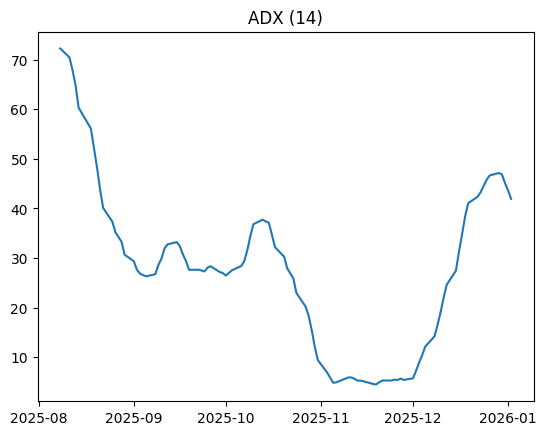

In [ ]:
n = 14
high = df['High']
low = df['Low']
close = df['Close']

plus_dm = high.diff()
minus_dm = low.diff().abs()
plus_dm[plus_dm < 0] = 0
minus_dm[minus_dm < 0] = 0

tr = pd.concat([
high - low,
(high - close.shift()).abs(),
(low - close.shift()).abs()
], axis=1).max(axis=1)

atr = tr.rolling(n).mean()
plus_di = 100 * (plus_dm.rolling(n).mean() / atr)
minus_di = 100 * (minus_dm.rolling(n).mean() / atr)

dx = (abs(plus_di - minus_di) / (plus_di + minus_di)) * 100
df['ADX_14'] = dx.rolling(n).mean()

plt.figure()
plt.plot(df['ADX_14'])
plt.title('ADX (14)')
plt.show()

2. Moving Average Convergence Divergence (MACD)
*   Purpose: Momentum + trend direction
*   Parameters used: Fast EMA = 12, Slow EMA = 26, Signal EMA = 9


*   Parameter effect: Smaller EMA periods → faster but noisy signals, Larger EMA periods → smoother but delayed







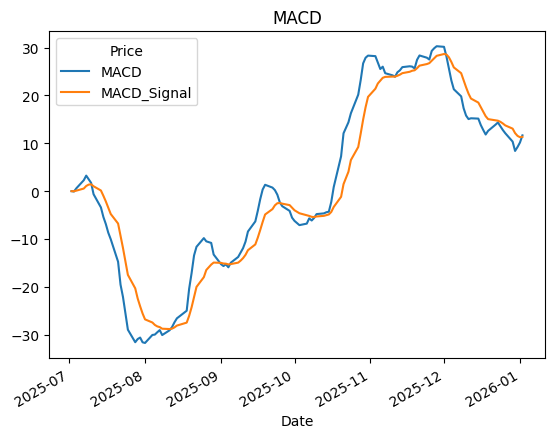

In [ ]:
ema12 = df['Close'].ewm(span=12, adjust=False).mean()
ema26 = df['Close'].ewm(span=26, adjust=False).mean()

df['MACD'] = ema12 - ema26
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()

df[['MACD','MACD_Signal']].plot(title='MACD')
plt.show()

Volume Indicators:
1. Volume Price Trend (VPT)


*   Purpose: Confirms price movement using volume
*   Interpretation: Rising VPT → volume supports price rise, Divergence → possible reversal



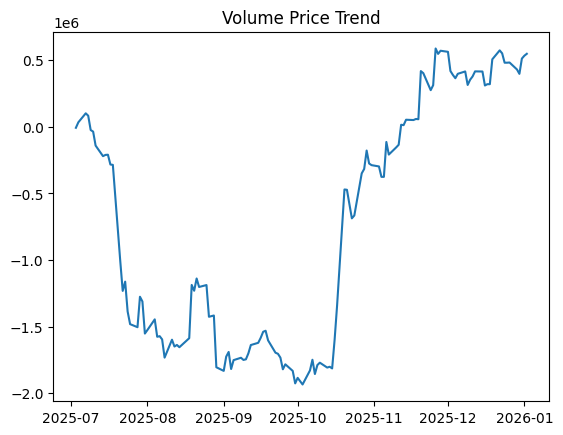

In [ ]:
df['VPT'] = (df['Volume'] * (df['Close'] - df['Close'].shift()) / df['Close'].shift()).cumsum()

plt.figure()
plt.plot(df['VPT'])
plt.title('Volume Price Trend')
plt.show()

2. Volume RSI


*   Purpose: Momentum of volume instead of price
*   Parameters: Lookback = 14


*   Interpretation: Above 70 → volume overbought, Below 30 → volume oversold





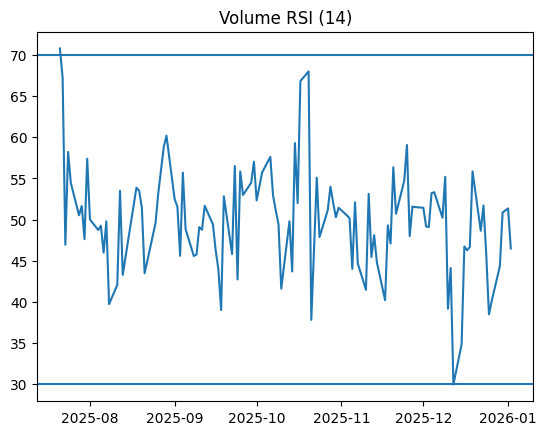

In [ ]:
n = 14
vol_delta = df['Volume'].diff()
gain = vol_delta.where(vol_delta > 0, 0)
loss = -vol_delta.where(vol_delta < 0, 0)

avg_gain = gain.rolling(n).mean()
avg_loss = loss.rolling(n).mean()

rs = avg_gain / avg_loss
df['Volume_RSI_14'] = 100 - (100 / (1 + rs))

plt.figure()
plt.plot(df['Volume_RSI_14'])
plt.axhline(70)
plt.axhline(30)
plt.title('Volume RSI (14)')
plt.show()

Volatility Indicators:
1. Donchian Channels


*   Purpose: Measures breakout volatility
*   Parameters: Lookback period = 20


*   Parameter effect: Smaller window → frequent breakouts, Larger window → stronger confirmation





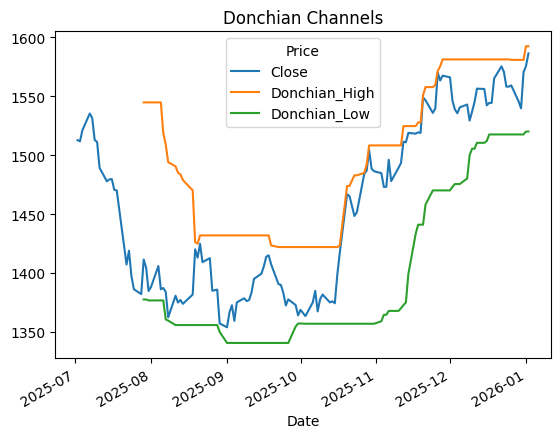

In [ ]:
n = 20
df['Donchian_High'] = df['High'].rolling(n).max()
df['Donchian_Low'] = df['Low'].rolling(n).min()

df[['Close','Donchian_High','Donchian_Low']].plot(title='Donchian Channels')
plt.show()

2. Average True Range (ATR)


*   Purpose: Measures market volatility
*   Parameters: Lookback = 14


*   Interpretation: Rising ATR → increasing volatility, Falling ATR → consolidation





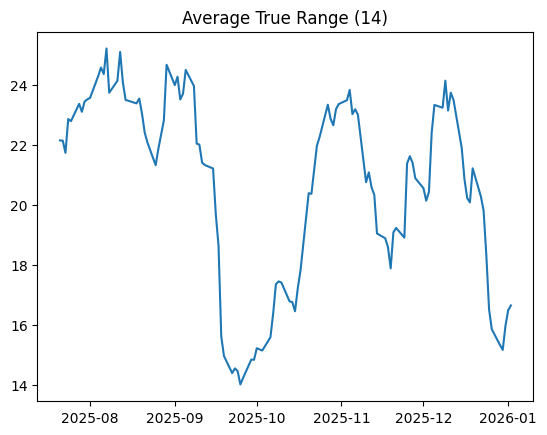

In [ ]:
tr = pd.concat([
df['High'] - df['Low'],
(df['High'] - df['Close'].shift()).abs(),
(df['Low'] - df['Close'].shift()).abs()
], axis=1).max(axis=1)

df['ATR_14'] = tr.rolling(14).mean()

plt.figure()
plt.plot(df['ATR_14'])
plt.title('Average True Range (14)')
plt.show()

# Q2. Design and Implement a Trading Strategy Using Technical Indicators

Financial markets change continuously due to many factors such as news, demand–supply, and investor behaviour. To make decisions systematically, traders use technical indicators instead of intuition. In this question, you will use technical indicators to build a rule-based trading strategy and test its performance on historical data.

The objective of this question is to design, implement, and evaluate a Python-based trading strategy using the technical indicators you implemented in Question 1.

**Task:**- Using the same stock data and the technical indicators chosen in Q1, design a trading strategy that generates buy and sell signals based on clearly defined rules.




**Requirements**:-  Your strategy must include the following components:

**1. Indicator Usage**

* Use one or more technical indicators implemented in Q1.

* Clearly state how each indicator is used in the strategy

**2. Signal Generation**
* Develop the logic for generating buy or sell signals based on the computed technical indicators. Define clear and
robust rules for triggering trading decisions.

**3. Backtesting**
* Create a comprehensive backtesting framework to
evaluate the performance of the trading strategy
* Assume an initial capital (e.g., ₹1,00,000).

**4.Performance Evaluation**
* You must compute and report the following metrics:-
  - Total profit
  - Net profit
  - Number of Winning Trades
  - Number of Losing Trades
  - Maximum Drawdown
  - Sharpe Ratio
  - Sortino Ratio

**5. Documentation**  
* Provide clear documentation for the imple-
mented trading strategy, including the rationale behind signal generation rules.


**6. Deliverables**

You must submit:

* A single .ipynb file containing:

  - Trading strategy code

  - Buy/Sell signal columns

  - Backtesting results

  - Performance metrics

  - Relevant plots (price with buy/sell signals)

Indicators Used:


*   MACD (12,26,9) – trend & momentum confirmation
*   ADX (14) – trend strength filter


*    ATR (14) – volatility-based risk control
Rationale:


*   MACD gives directional signals (crossovers)
*   ADX ensures we trade only strong trends

*   ATR helps manage risk dynamically

Signal Generation Rules:


1.   Buy Signal


*   MACD crosses above Signal line
*   ADX > 25 (strong trend)


2.   Sell Signal


*   MACD crosses below Signal line
*   OR price hits ATR-based stop-loss















In [ ]:
# MACD
ema12 = df['Close'].ewm(span=12, adjust=False).mean()
ema26 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD'] = ema12 - ema26
df['Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()

# ADX
n = 14
high, low, close = df['High'], df['Low'], df['Close']
plus_dm = high.diff().clip(lower=0)
minus_dm = low.diff().abs().clip(lower=0)

tr = pd.concat([
    high - low,
    (high - close.shift()).abs(),
    (low - close.shift()).abs()
], axis=1).max(axis=1)

atr = tr.rolling(n).mean()
df['ATR'] = atr

plus_di = 100 * (plus_dm.rolling(n).mean() / atr)
minus_di = 100 * (minus_dm.rolling(n).mean() / atr)
dx = (abs(plus_di - minus_di) / (plus_di + minus_di)) * 100
df['ADX'] = dx.rolling(n).mean()

# Signal Generation
df['Buy'] = (df['MACD'] > df['Signal']) & (df['MACD'].shift() <= df['Signal'].shift()) & (df['ADX'] > 25)
df['Sell'] = (df['MACD'] < df['Signal']) & (df['MACD'].shift() >= df['Signal'].shift())

# Backtesting Engine
capital = 100000
position = 0
entry_price = 0
stop_loss = 0
profits = []

for i in range(len(df)):
    if df['Buy'].iloc[i] and position == 0:
        position = capital / df['Close'].iloc[i]
        entry_price = df['Close'].iloc[i]
        stop_loss = entry_price - 2 * df['ATR'].iloc[i]
        capital = 0

    elif position > 0:
        # Stop-loss condition
        if df['Close'].iloc[i] < stop_loss or df['Sell'].iloc[i]:
            capital = position * df['Close'].iloc[i]
            profits.append(capital - 100000)
            position = 0

final_value = capital if position == 0 else position * df['Close'].iloc[-1]
net_profit = final_value - 100000

# Performance Metrics
returns = pd.Series(profits)

winning_trades = (returns > 0).sum()
losing_trades = (returns <= 0).sum()

sharpe = returns.mean() / returns.std() if returns.std() != 0 else 0
sortino = returns.mean() / returns[returns < 0].std() if len(returns[returns < 0]) > 0 else 0

cumulative = returns.cumsum()
drawdown = cumulative - cumulative.cummax()
max_dd = drawdown.min()

print("Final Portfolio Value:", final_value)
print("Net Profit:", net_profit)
print("Winning Trades:", winning_trades)
print("Losing Trades:", losing_trades)
print("Max Drawdown:", max_dd)
print("Sharpe Ratio:", sharpe)
print("Sortino Ratio:", sortino)

Final Portfolio Value: 106633.96064638392
Net Profit: 6633.960646383915
Winning Trades: 1
Losing Trades: 2
Max Drawdown: -1341.8134393162181
Sharpe Ratio: 0.26928043439831645
Sortino Ratio: 9.52970682271692


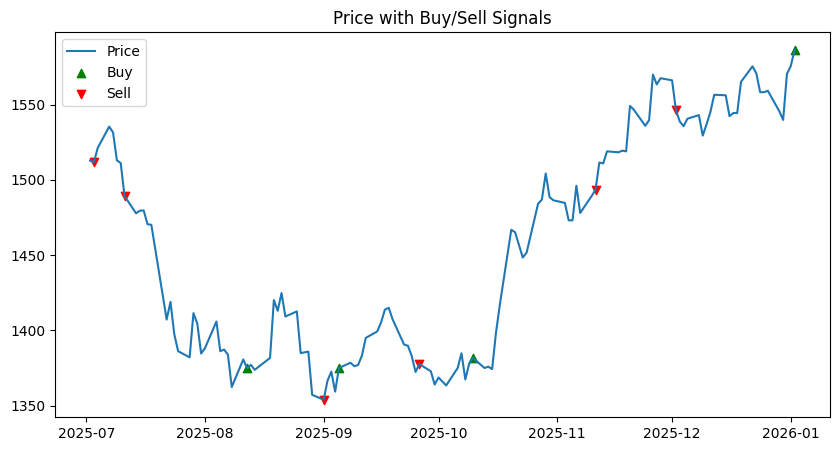

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df['Close'], label='Price')
plt.scatter(df[df['Buy']].index, df[df['Buy']]['Close'], marker='^', color='g', label='Buy')
plt.scatter(df[df['Sell']].index, df[df['Sell']]['Close'], marker='v', color='r', label='Sell')
plt.legend()
plt.title('Price with Buy/Sell Signals')
plt.show()